# Mahomet Moisture Observatory — Scientific Analysis Notebook
**NASA Space Apps Challenge 2026 | Team Intergalactic Harvester (`Dancing with the SARs`)**

---

### Overview & Purpose
This reproducible notebook investigates **near-surface soil moisture dynamics, precipitation forcing, and groundwater monitoring patterns** across the **Mahomet Aquifer region of central Illinois** between **July 2 and October 18, 2026**.

It serves as the scientific companion to our interactive web observatory (`app/`), synthesizing multi-sensor Earth observations and ground monitoring networks:
1. **NASA NISAR L3 Soil Moisture (SME2):** Volumetric near-surface soil moisture ($\text{m}^3/\text{m}^3$, top ~0–5 cm) across **9 orbital acquisitions** (`2026-07-02` to `2026-10-18`).
2. **NOAA Multi-Radar Multi-Sensor (MRMS) Precipitation:** Hourly radar-derived rainfall grids (`11,064` aquifer cells) aligned to exact NISAR overpass timestamps.
3. **Illinois State Water Survey (ISWS) Groundwater Network:** Continuous 2026 telemetry across **47 active observation wells** (out of 102 cataloged wells) plus a **12-year historical seasonal record (2015–2026)**.

> **Reproducibility Note:** Rather than requiring users to download multi-gigabyte raw NISAR HDF5 granules or thousands of hourly MRMS Parquet archives, this notebook runs directly on the lightweight, curated summary tables stored in `data/summaries/` and `data/wells/` (locally or via GitHub raw URLs in Google Colab).

## 0. Environment & Data Path Configuration
The cell below configures data paths so that the notebook executes seamlessly in **local Jupyter/VS Code** (whether launched from `notebooks/` or the repository root) as well as in a **fresh Google Colab session** (falling back automatically to the public GitHub repository raw files if local folders are not present).

In [2]:
import os
import json
import urllib.request
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns
from scipy import stats

# Plotting style harmonized with the Mahomet Moisture Observatory web palette
plt.rcParams.update({
    'figure.dpi': 130,
    'savefig.dpi': 200,
    'font.sans-serif': 'DejaVu Sans',
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.25,
    'grid.linestyle': '--',
})

PALETTE = {
    'navy': '#1B365D',
    'teal': '#1F7A8C',
    'sky': '#4EA8DE',
    'amber': '#E07A5F',
    'sand': '#F2CC8F',
    'olive': '#3D5A45',
    'slate': '#5C677D',
    'crimson': '#B5173B',
}

# Locate repository root or fallback to GitHub raw URLs for standalone Colab execution
GITHUB_RAW_BASE = "https://raw.githubusercontent.com/wayward710/IntergalacticHarvester/main"

def resolve_repo_paths():
    candidates = [Path.cwd(), Path.cwd().parent, Path('/content/IntergalacticHarvester')]
    for base in candidates:
        if (base / 'data' / 'summaries').exists():
            fig_dir = base / 'assets' / 'figures'
            fig_dir.mkdir(parents=True, exist_ok=True)
            return str(base / 'data'), str(fig_dir), False
    # Standalone Colab fallback (streams curated CSV/JSON directly from GitHub)
    fig_dir = Path('/content/mahomet_figures')
    fig_dir.mkdir(parents=True, exist_ok=True)
    return f"{GITHUB_RAW_BASE}/data", str(fig_dir), True

DATA_BASE, FIG_DIR, IS_REMOTE = resolve_repo_paths()
print(f"Data source mode : {'Remote GitHub Raw' if IS_REMOTE else 'Local Repository'}")
print(f"DATA_BASE        : {DATA_BASE}")
print(f"FIG_DIR          : {FIG_DIR}")

def load_csv(rel_path):
    return pd.read_csv(f"{DATA_BASE}/{rel_path}")

def load_json(rel_path):
    target = f"{DATA_BASE}/{rel_path}"
    if target.startswith("http"):
        with urllib.request.urlopen(target) as resp:
            return json.loads(resp.read().decode("utf-8"))
    with open(target, "r", encoding="utf-8") as f:
        return json.load(f)

Data source mode : Local Repository
DATA_BASE        : /tmp/IntergalacticHarvester_stage/data
FIG_DIR          : /tmp/IntergalacticHarvester_stage/assets/figures


## 1. Study Area & Multi-Sensor Observation Network
The **Mahomet Aquifer** is a major buried glacial sand-and-gravel aquifer system underlying east-central Illinois (spanning ~39.9°N to 40.9°N, 87.5°W to 90.1°W), supplying municipal, industrial, and agricultural water across the region.

To examine how surface soil moisture responds to summer/autumn precipitation and relates to subsurface hydrogeology, we combine:
- **6,710 matched MRMS radar grid cells** containing **137,532 common NISAR L3 SME2 pixels** (out of **137,553** total common NISAR pixels across the aquifer).
- **102 cataloged ISWS groundwater observation wells** (82 in the Mahomet Aquifer, 19 in the overlying Glasford Aquifer, and 1 in the Henry Aquifer), including **47 continuously telemetered wells** active throughout the 2026 NISAR campaign.

Matched MRMS cells over Mahomet Aquifer : 6,710
Total NISAR pixels in matched cells     : 137,532
Latitude range                          : 39.945°N to 40.855°N
Longitude range                         : -89.945°W to -87.535°W
Cataloged ISWS wells                    : 102 (Active 2026 telemetry: 47)


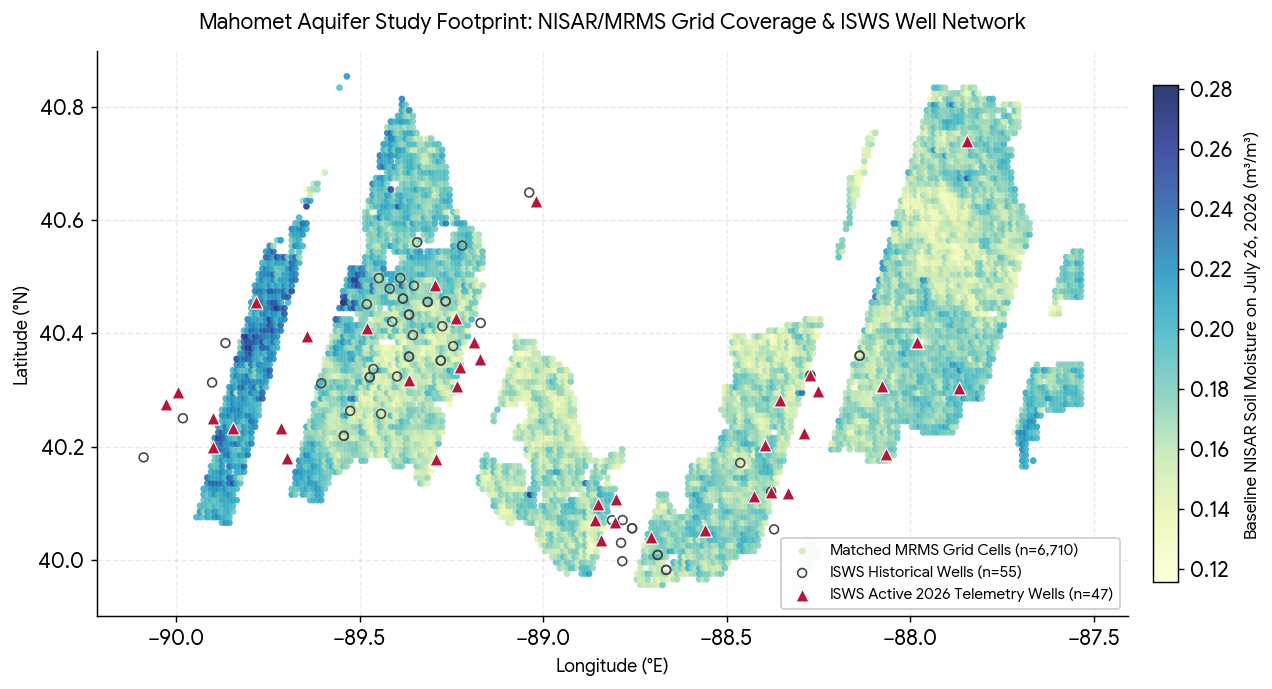

In [4]:
# Load spatial grid cell summaries and ISWS well metadata
cells_df = load_csv("summaries/initial_moisture_mrms_cells.csv")
wells_df = load_csv("wells/well_metadata.csv")
well_cov_df = load_csv("wells/isws_well_coverage.csv")
active_wells = wells_df.merge(
    well_cov_df[['well', 'study_observations', 'study_day_coverage_pct']],
    on='well',
    how='left'
)

print(f"Matched MRMS cells over Mahomet Aquifer : {len(cells_df):,}")
print(f"Total NISAR pixels in matched cells     : {cells_df['pixel_count'].sum():,}")
print(f"Latitude range                          : {cells_df['latitude'].min():.3f}°N to {cells_df['latitude'].max():.3f}°N")
print(f"Longitude range                         : {cells_df['longitude'].min():.3f}°W to {cells_df['longitude'].max():.3f}°W")
print(f"Cataloged ISWS wells                    : {len(wells_df)} (Active 2026 telemetry: {(active_wells['study_observations'] > 0).sum()})")

# Plot spatial footprint of the Mahomet Aquifer cells and ISWS monitoring network
fig, ax = plt.subplots(figsize=(10.5, 5.4))

sc = ax.scatter(
    cells_df['longitude'], cells_df['latitude'],
    c=cells_df['initial'], cmap='YlGnBu', s=14, alpha=0.85, edgecolors='none',
    label='Matched MRMS Grid Cells (n=6,710)'
)
cbar = plt.colorbar(sc, ax=ax, pad=0.02, shrink=0.88)
cbar.set_label('Baseline NISAR Soil Moisture on July 26, 2026 (m³/m³)', fontsize=9.5)

# Overlay optional GeoJSON boundary if placed in data/boundaries/mahomet_aquifer.geojson
geojson_local = Path(DATA_BASE) / 'boundaries' / 'mahomet_aquifer.geojson'
if not IS_REMOTE and geojson_local.exists():
    import geopandas as gpd
    gdf_bound = gpd.read_file(geojson_local).to_crs('EPSG:4326')
    gdf_bound.boundary.plot(ax=ax, color=PALETTE['navy'], linewidth=1.6, label='Mahomet Aquifer Boundary')

# Plot ISWS wells
hist_w = active_wells[active_wells['study_observations'] == 0]
act_w = active_wells[active_wells['study_observations'] > 0]
ax.scatter(hist_w['longitude'], hist_w['latitude'], marker='o', s=24, facecolors='none',
           edgecolors='#444444', linewidths=0.9, label='ISWS Historical Wells (n=55)', zorder=4)
ax.scatter(act_w['longitude'], act_w['latitude'], marker='^', s=52, color=PALETTE['crimson'],
           edgecolors='white', linewidths=0.6, label='ISWS Active 2026 Telemetry Wells (n=47)', zorder=5)

ax.set_title('Mahomet Aquifer Study Footprint: NISAR/MRMS Grid Coverage & ISWS Well Network', fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel('Longitude (°E)', fontsize=10)
ax.set_ylabel('Latitude (°N)', fontsize=10)
ax.legend(loc='lower right', frameon=True, facecolor='white', framealpha=0.92, fontsize=8.5)
plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig1_study_area_footprint.png")
plt.show()

## 2. Data Quality, Coverage & Fixed-Footprint Comparability
### Why a Fixed / Common Footprint Matters
In orbital SAR soil moisture retrievals (NISAR L3 SME2), the set of valid pixels can shift slightly between passes due to retrieval quality flags, surface water masks, or swath edge geometry. Comparing naive date-by-date averages across different spatial subsets can conflate genuine hydrological change with spatial sampling shifts.

To eliminate coverage bias, all multi-date comparisons in this study restrict analysis to the **137,553 common pixels** valid across **all nine 2026 acquisitions**.

### Audit of Supporting Datasets (MRMS & ISWS)
- **NOAA MRMS Hourly Collection (`2026-06-20` to `2026-10-19`, 122 days / 2,928 hours):**
  - `1,838` hourly Parquet files ingested with **0 read errors** (`mrms_read_errors.csv`).
  - Exactly **1 duplicate timestamp** (`2026-09-21T21:00:00Z`, 2 files) with **0 conflicting cell values** (`mrms_duplicate_hours.csv`).
  - `1,091` hours without files correspond to dry periods where zero precipitation was archived over Illinois; these are explicitly flagged (`uncertain_missing_file = True`) and zero-filled (`assumed_zero_raw = 0.0`) rather than silently ignored.
- **ISWS Groundwater Telemetry (`2026-07-02` to `2026-10-18`, 109 days):**
  - `47` active telemetry wells recorded `118,756` hourly observations (`4,964` well-days; mean `23.92` readings/day).
  - `41` of the `47` active wells achieved **100% daily coverage** (`109/109` days), and `42–47` active wells have valid measurements coinciding with each of the nine NISAR acquisitions.

In [6]:
# Audit MRMS daily completeness & ISWS acquisition-date coverage
mrms_daily = load_csv("summaries/mrms_aquifer_daily.csv")
mrms_hourly = load_csv("summaries/mrms_aquifer_hourly.csv")
mrms_dup = load_csv("summaries/mrms_duplicate_hours.csv")

total_hours = len(mrms_hourly)
present_hours = int(mrms_hourly['file_present'].sum())
missing_hours = int(mrms_hourly['uncertain_missing_file'].sum())
complete_days = int(mrms_daily['complete_hourly_coverage'].sum())

print("=== NOAA MRMS Hourly & Daily Coverage Audit (2026-06-20 to 2026-10-19) ===")
print(f"Total hours in 122-day window      : {total_hours:,}")
print(f"Hours with MRMS Parquet file       : {present_hours:,} ({present_hours/total_hours*100:.1f}%)")
print(f"Dry/unarchived hours (zero-filled) : {missing_hours:,} ({missing_hours/total_hours*100:.1f}%)")
print(f"Days with 24/24 hourly files       : {complete_days} / {len(mrms_daily)} days")
print(f"Duplicate hour timestamps          : {len(mrms_dup)} (conflicting values: {int(mrms_dup['conflicting_values'].sum())})")
print(f"122-day cumulative aquifer rain    : {mrms_daily['provisional_sum_raw'].sum():.2f} in (provisional)")

peak_day = mrms_daily.loc[mrms_daily['provisional_sum_raw'].idxmax()]
print(f"Single-day peak rainfall           : {peak_day['provisional_sum_raw']:.4f} in on {peak_day['date_utc'][:10]} (wet area fraction: {peak_day['max_wet_area_fraction']*100:.1f}%)")

print("\n=== ISWS Active Telemetry Wells Near Each NISAR Overpass ===")
near_cols = [c for c in well_cov_df.columns if c.startswith('near_')]
cov_summary = pd.DataFrame({
    'NISAR Date': [f"{c[5:9]}-{c[9:11]}-{c[11:13]}" for c in near_cols],
    'Active Wells with Coincident Reading': [int(well_cov_df[c].notna().sum()) for c in near_cols]
})
print(cov_summary.to_string(index=False))

=== NOAA MRMS Hourly & Daily Coverage Audit (2026-06-20 to 2026-10-19) ===
Total hours in 122-day window      : 2,928
Hours with MRMS Parquet file       : 1,837 (62.7%)
Dry/unarchived hours (zero-filled) : 1,091 (37.3%)
Days with 24/24 hourly files       : 33 / 122 days
Duplicate hour timestamps          : 1 (conflicting values: 0)
122-day cumulative aquifer rain    : 16.99 in (provisional)
Single-day peak rainfall           : 2.5218 in on 2026-08-15 (wet area fraction: 100.0%)

=== ISWS Active Telemetry Wells Near Each NISAR Overpass ===
NISAR Date  Active Wells with Coincident Reading
2026-07-02                                    47
2026-07-14                                    46
2026-07-26                                    46
2026-08-19                                    47
2026-08-31                                    46
2026-09-12                                    46
2026-09-24                                    46
2026-10-06                                    43
2026-10-18    

## 3. Soil Moisture Trajectory & Eight Consecutive Intervals
Evaluating the **137,553 common NISAR L3 SME2 pixels** across all nine acquisition dates reveals three distinct hydrological phases during the 2026 growing-to-harvest season:
1. **Early-to-Mid July Drying (`July 2 → July 26`):** Basin-mean soil moisture declined from **0.2317** to **0.1823 m³/m³** (`-0.0494 m³/m³` between July 2 and July 14, with only `16.6%` of pixels wetting) and edged further down to **0.1741 m³/m³** by July 26.
2. **Major Late-Summer Wetting Surge (`July 26 → August 19`):** Following heavy August storms (`8.16 in` interval rainfall), mean soil moisture surged by **+0.0682 m³/m³** (`+39.2%` relative increase) to **0.2424 m³/m³**, wetting **99.29%** of all common pixels.
3. **Late-Summer Persistence & Autumn Drawdown (`August 19 → October 18`):** Soil moisture remained elevated above `0.216 m³/m³` through late September (including a modest rebound of `+0.0044 m³/m³` during September 12–24), before dropping sharply by **-0.0440 m³/m³** (`September 24 → October 6`) and ending at **0.1647 m³/m³** on October 18.

=== Eight Consecutive NISAR Soil Moisture Intervals (n = 137,553 Common Pixels) ===
start_date   end_date  days  initial_mean  final_mean  mean_change  median_change  fraction_wetter  initial_final_r
2026-07-02 2026-07-14    12        0.2317      0.1823      -0.0494        -0.0511           0.1662           0.6608
2026-07-14 2026-07-26    12        0.1823      0.1741      -0.0082        -0.0070           0.4194           0.4428
2026-07-26 2026-08-19    24        0.1741      0.2424       0.0682         0.0703           0.9929           0.5977
2026-08-19 2026-08-31    12        0.2424      0.2271      -0.0152        -0.0178           0.2341           0.5696
2026-08-31 2026-09-12    12        0.2271      0.2166      -0.0105        -0.0121           0.2897           0.5480
2026-09-12 2026-09-24    12        0.2166      0.2210       0.0044         0.0122           0.5993           0.3891
2026-09-24 2026-10-06    12        0.2210      0.1770      -0.0440        -0.0417           0.0808      

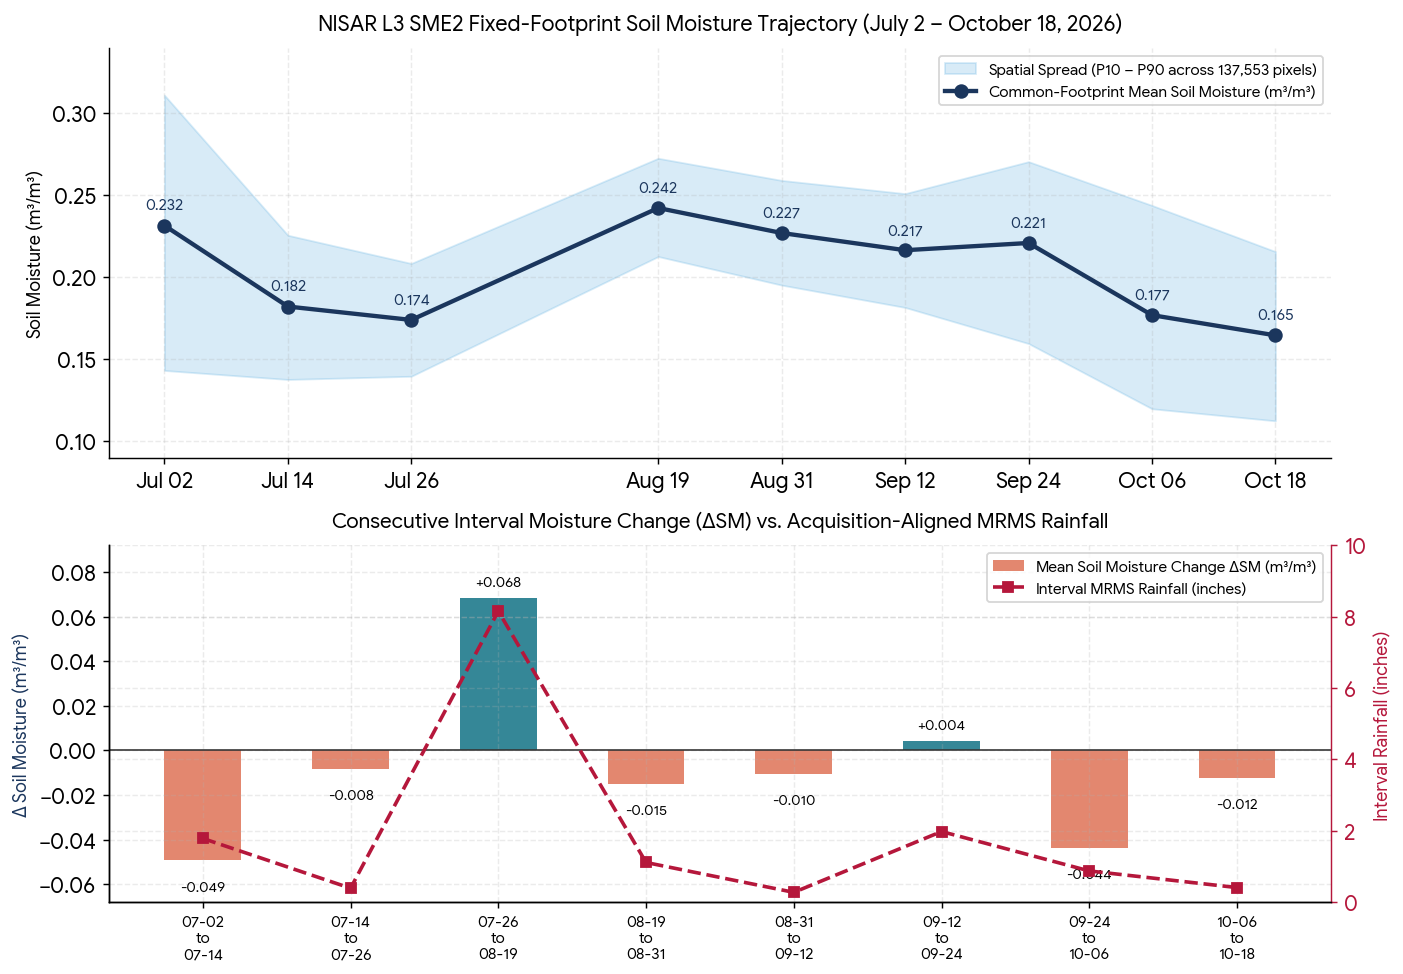

In [8]:
ts_df = load_csv("summaries/fixed_footprint_timeseries.csv")
isum_df = load_csv("summaries/interval_summary.csv")
aligned_df = load_csv("summaries/nisar_mrms_aligned.csv")

# Display formatted 8-interval summary table
display_cols = [
    'start_date', 'end_date', 'days', 'initial_mean', 'final_mean',
    'mean_change', 'median_change', 'fraction_wetter', 'initial_final_r'
]
print("=== Eight Consecutive NISAR Soil Moisture Intervals (n = 137,553 Common Pixels) ===")
print(isum_df[display_cols].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Figure 2: Two-panel time series (Common-footprint Soil Moisture + Interval Change & Rainfall)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(11, 7.6), sharex=False, gridspec_kw={'height_ratios': [1.15, 1]})

dates_dt = pd.to_datetime(ts_df['date'])

# Panel A: Soil Moisture Trajectory with P10-P90 spatial spread
ax1.fill_between(
    dates_dt, ts_df['p10_m3_m3'], ts_df['p90_m3_m3'],
    color=PALETTE['sky'], alpha=0.22, label='Spatial Spread (P10 – P90 across 137,553 pixels)'
)
ax1.plot(
    dates_dt, ts_df['mean_soil_moisture_m3_m3'],
    color=PALETTE['navy'], marker='o', linewidth=2.4, markersize=7,
    label='Common-Footprint Mean Soil Moisture (m³/m³)'
)
for dt_val, sm_val in zip(dates_dt, ts_df['mean_soil_moisture_m3_m3']):
    ax1.annotate(
        f"{sm_val:.3f}", (dt_val, sm_val),
        textcoords="offset points", xytext=(0, 9), ha='center', fontsize=8.5, fontweight='bold', color=PALETTE['navy']
    )

ax1.set_ylim(0.09, 0.34)
ax1.set_ylabel('Soil Moisture (m³/m³)', fontsize=10)
ax1.set_title('NISAR L3 SME2 Fixed-Footprint Soil Moisture Trajectory (July 2 – October 18, 2026)', fontsize=12, fontweight='bold', pad=10)
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax1.set_xticks(dates_dt)
ax1.legend(loc='upper right', frameon=True, facecolor='white', fontsize=8.5)

# Panel B: Interval Soil Moisture Change (bars) vs Interval Rainfall (line on twin axis)
int_labels = [f"{r['start_date'][5:]}\nto\n{r['end_date'][5:]}" for _, r in isum_df.iterrows()]
x_idx = np.arange(len(isum_df))
bar_colors = [PALETTE['teal'] if v >= 0 else PALETTE['amber'] for v in isum_df['mean_change']]

bars = ax2.bar(x_idx, isum_df['mean_change'], width=0.52, color=bar_colors, edgecolor='none', alpha=0.9, label='Mean Soil Moisture Change ΔSM (m³/m³)')
ax2.axhline(0, color='#333333', linewidth=0.9)
ax2.set_ylabel('Δ Soil Moisture (m³/m³)', fontsize=10, color=PALETTE['navy'])
ax2.set_ylim(-0.068, 0.092)
ax2.set_xticks(x_idx)
ax2.set_xticklabels(int_labels, fontsize=8.5)

for bar, val in zip(bars, isum_df['mean_change']):
    y_pos = val + (0.004 if val >= 0 else -0.009)
    ax2.text(bar.get_x() + bar.get_width()/2, y_pos, f"{val:+.3f}", ha='center', va='bottom' if val >= 0 else 'top', fontsize=8, fontweight='bold')

ax2_rain = ax2.twinx()
ax2_rain.spines['top'].set_visible(False)
ax2_rain.spines['right'].set_visible(True)
ax2_rain.spines['right'].set_color(PALETTE['crimson'])
rain_vals = aligned_df['interval_rain_provisional_inches'].dropna().values
ax2_rain.plot(x_idx, rain_vals, color=PALETTE['crimson'], marker='s', linewidth=2.0, linestyle='--', markersize=6, label='Interval MRMS Rainfall (inches)')
ax2_rain.set_ylabel('Interval Rainfall (inches)', fontsize=10, color=PALETTE['crimson'])
ax2_rain.tick_params(axis='y', colors=PALETTE['crimson'])
ax2_rain.set_ylim(0, 10.0)

# Combined legend for Panel B
lines1, labels1 = ax2.get_legend_handles_labels()
lines2, labels2 = ax2_rain.get_legend_handles_labels()
ax2.legend(lines1 + lines2, labels1 + labels2, loc='upper right', frameon=True, facecolor='white', fontsize=8.5)
ax2.set_title('Consecutive Interval Moisture Change (ΔSM) vs. Acquisition-Aligned MRMS Rainfall', fontsize=11.5, fontweight='bold', pad=10)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig2_interval_changes_and_rainfall.png")
plt.show()

## 4. NOAA MRMS Rainfall Context & Spatial Comparisons
### Temporal Coupling Across Intervals
Comparing basin-averaged soil moisture changes ($\Delta\text{SM}$) against exact overpass-aligned precipitation totals (`nisar_mrms_aligned.csv`) highlights the critical role of **rainfall timing**:
- **Full inter-acquisition rainfall (`12–24 days`):** Strong positive correlation ($r = 0.8135$, $p = 0.014$), but driven by the Jul 26 – Aug 19 storm: $r = -0.17$ without that interval ($n = 7$).
- **Prior 7-day cumulative rainfall:** Slightly stronger correlation ($r = 0.8167$, $p = 0.013$; $r = -0.54$ without the storm interval, $n = 7$), reflecting that near-surface soil moisture responds primarily to rainfall occurring within the week preceding satellite overpass.
- **Prior 3-day rainfall alone:** Weak correlation ($r = 0.2349$), because the largest storm of the season (**2.52 in on August 15**) occurred **3.5 days prior** to the August 19 (`00:50 UTC`) NISAR acquisition—falling just outside the 72-hour window while captured inside the 7-day window (`5.90 in`).

### Contrasting Spatial Regimes: Widespread Storm vs. East–West Gradient
At the individual MRMS grid-cell level (`6,710` matched cells), spatial correlation between local rainfall and local $\Delta\text{SM}$ depends strongly on storm structure:
1. **July 26 – August 19 (`mean rain = 8.46 in`, range `3.22–14.99 in`):** Heavy rainfall saturated upper soil layers across virtually the entire aquifer (`99.29%` of pixels wetted), yielding a near-zero cell-level spatial correlation ($r = -0.0537$) because spatial variation in $\Delta\text{SM}$ was governed primarily by **pre-storm soil dryness** rather than differences between 6 inches and 12 inches of rain.
2. **September 12 – September 24 (`mean rain = 2.01 in`, range `0.86–6.34 in`):** Moderate, spatially uneven rainfall produced a positive cell-level correlation ($r = 0.2383$) and a clear **west-to-east moisture gradient** (`longitude_quartiles.csv`), transitioning from net drying in the west quartile (`mean ΔSM = -0.0089 m³/m³`, `1.65 in` rain) to strong wetting in the east quartile (`mean ΔSM = +0.0193 m³/m³`, `2.22 in` rain).

=== Temporal Correlation with Interval Soil Moisture Change ΔSM (n = 8 intervals) ===
  Prior 3-Day Rainfall (in)     : Pearson r = +0.2349 (p = 0.5754)
  Prior 7-Day Rainfall (in)     : Pearson r = +0.8167 (p = 0.0134)
  Prior 12-Day Rainfall (in)    : Pearson r = +0.7846 (p = 0.0211)
  Full Interval Rainfall (in)   : Pearson r = +0.8135 (p = 0.0140)

=== West-to-East Gradient (September 12 – September 24, 2026) ===
longitude_quartile  cells  median_change  mean_change  fraction_wetter  mean_interval_rain  mean_3day_rain
              west   1678        -0.0074      -0.0089           0.4076              1.6512          0.0147
      west-central   1677         0.0029      -0.0006           0.5492              2.0139          0.1283
      east-central   1677         0.0124       0.0100           0.7048              2.1572          0.2753
              east   1678         0.0236       0.0193           0.8087              2.2170          0.0864


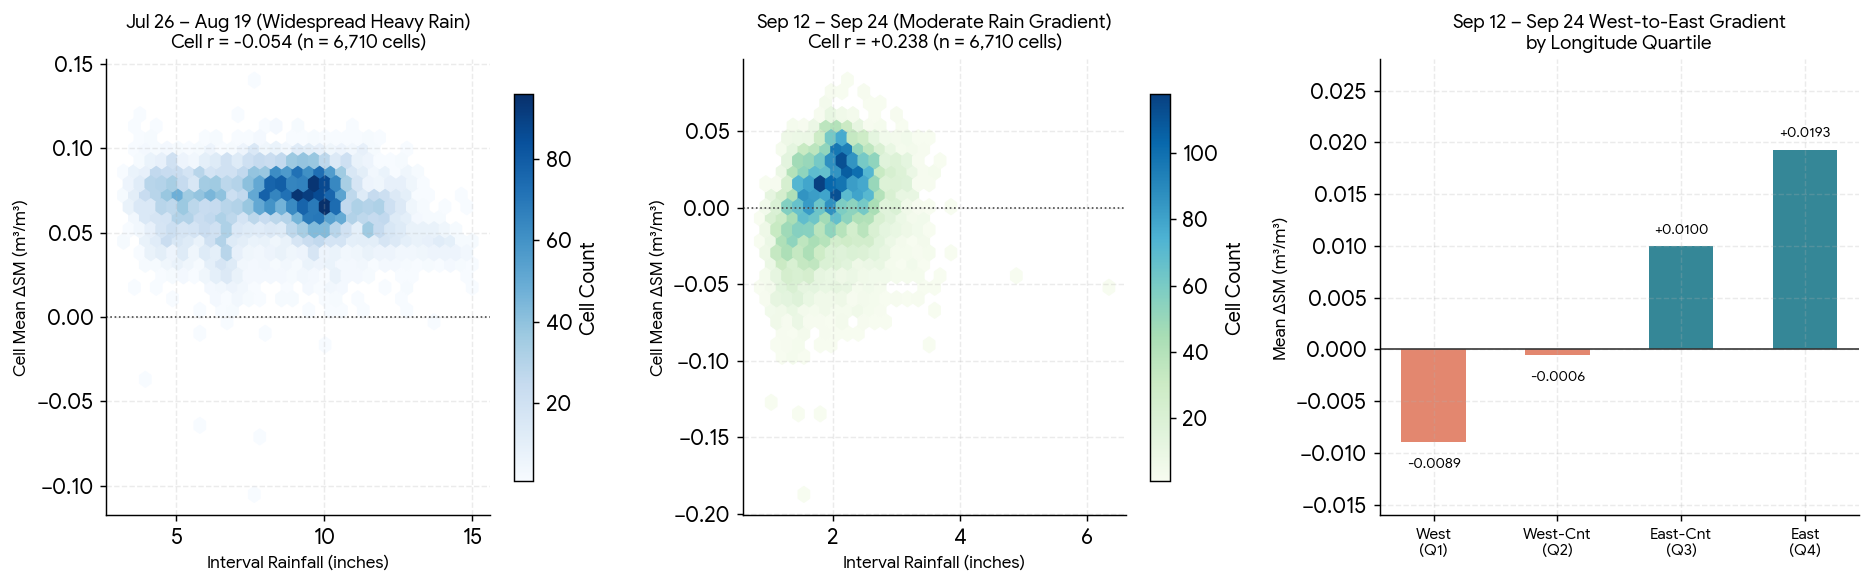

In [10]:
# Compute temporal correlations across antecedent rainfall windows
valid_aligned = aligned_df.dropna(subset=['soil_moisture_change_m3_m3']).copy()
print("=== Temporal Correlation with Interval Soil Moisture Change ΔSM (n = 8 intervals) ===")
for col, label in [
    ('prior_3d_rain_provisional_inches', 'Prior 3-Day Rainfall (in)'),
    ('prior_7d_rain_provisional_inches', 'Prior 7-Day Rainfall (in)'),
    ('prior_12d_rain_provisional_inches', 'Prior 12-Day Rainfall (in)'),
    ('interval_rain_provisional_inches', 'Full Interval Rainfall (in)')
]:
    r_val, p_val = stats.pearsonr(valid_aligned[col], valid_aligned['soil_moisture_change_m3_m3'])
    print(f"  {label:<30}: Pearson r = {r_val:+.4f} (p = {p_val:.4f})")

# Load cell-level spatial comparisons & longitude quartiles
comp_aug = load_csv("summaries/mrms_cell_nisar_comparison_jul26_aug19.csv")
comp_sep = load_csv("summaries/mrms_cell_nisar_comparison_sep12_sep24.csv")
lon_q = load_csv("summaries/longitude_quartiles.csv")

print("\n=== West-to-East Gradient (September 12 – September 24, 2026) ===")
print(lon_q.to_string(index=False, float_format=lambda x: f"{x:.4f}"))

# Figure 3: Spatial comparison panels (Jul 26-Aug 19 vs Sep 12-Sep 24 + Longitude Quartiles)
fig, axes = plt.subplots(1, 3, figsize=(14.5, 4.6))

# Panel 1: Jul 26 - Aug 19 Hexbin
hb1 = axes[0].hexbin(
    comp_aug['rain_provisional_inches'], comp_aug['mean_nisar_change_m3_m3'],
    gridsize=32, cmap='Blues', mincnt=1
)
axes[0].axhline(0, color='#444444', linestyle=':', linewidth=0.9)
r_aug = comp_aug['rain_provisional_inches'].corr(comp_aug['mean_nisar_change_m3_m3'])
axes[0].set_title(f"Jul 26 – Aug 19 (Widespread Heavy Rain)\nCell r = {r_aug:+.3f} (n = 6,710 cells)", fontsize=10.5, fontweight='bold')
axes[0].set_xlabel('Interval Rainfall (inches)', fontsize=9.5)
axes[0].set_ylabel('Cell Mean ΔSM (m³/m³)', fontsize=9.5)
plt.colorbar(hb1, ax=axes[0], label='Cell Count', shrink=0.85)

# Panel 2: Sep 12 - Sep 24 Hexbin
hb2 = axes[1].hexbin(
    comp_sep['rain_interval_provisional_inches'], comp_sep['nisar_mean_change'],
    gridsize=32, cmap='GnBu', mincnt=1
)
axes[1].axhline(0, color='#444444', linestyle=':', linewidth=0.9)
r_sep = comp_sep['rain_interval_provisional_inches'].corr(comp_sep['nisar_mean_change'])
axes[1].set_title(f"Sep 12 – Sep 24 (Moderate Rain Gradient)\nCell r = {r_sep:+.3f} (n = 6,710 cells)", fontsize=10.5, fontweight='bold')
axes[1].set_xlabel('Interval Rainfall (inches)', fontsize=9.5)
axes[1].set_ylabel('Cell Mean ΔSM (m³/m³)', fontsize=9.5)
plt.colorbar(hb2, ax=axes[1], label='Cell Count', shrink=0.85)

# Panel 3: Longitude quartiles bar (Sep 12 - Sep 24)
qx = np.arange(len(lon_q))
q_colors = [PALETTE['amber'] if v < 0 else PALETTE['teal'] for v in lon_q['mean_change']]
qbars = axes[2].bar(qx, lon_q['mean_change'], width=0.52, color=q_colors, alpha=0.9, label='Mean ΔSM (m³/m³)')
axes[2].axhline(0, color='#333333', linewidth=0.9)
axes[2].set_xticks(qx)
axes[2].set_xticklabels(['West\n(Q1)', 'West-Cnt\n(Q2)', 'East-Cnt\n(Q3)', 'East\n(Q4)'], fontsize=8.5)
axes[2].set_ylabel('Mean ΔSM (m³/m³)', fontsize=9.5)
axes[2].set_ylim(-0.016, 0.028)
axes[2].set_title('Sep 12 – Sep 24 West-to-East Gradient\nby Longitude Quartile', fontsize=10.5, fontweight='bold')
for b, v in zip(qbars, lon_q['mean_change']):
    axes[2].text(b.get_x() + b.get_width()/2, v + (0.0012 if v >= 0 else -0.0025), f"{v:+.4f}", ha='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig3_spatial_rainfall_vs_moisture.png")
plt.show()

## 5. Antecedent Wetness & Initial-Moisture Stratification
Why did different parts of the Mahomet Aquifer gain different amounts of moisture during the **July 26 – August 19** storm period even when rainfall was heavy across the entire basin?

Partitioning the `137,553` common pixels (and `6,710` matched MRMS cells) into **10 equal-count deciles** ranked by initial soil moisture on July 26 (`initial_moisture_deciles_pixels.csv` & `initial_moisture_deciles_mrms_cells.csv`) reveals a monotonic gradient:
- **Driest initial decile (`Decile 1`, median initial SM = `0.1317 m³/m³`):** Gained a mean of **+0.0880 m³/m³** (interquartile range `+0.0785` to `+0.0981 m³/m³`), reaching `0.2172 m³/m³` on August 19.
- **Wettest initial decile (`Decile 10`, median initial SM = `0.2218 m³/m³`):** Gained a mean of **+0.0373 m³/m³** (`+0.0214` to `+0.0531 m³/m³`), reaching `0.2641 m³/m³` on August 19.

### Statistical Caution: Association vs. Physical Causation
Because $\Delta\text{SM} = \text{SM}_{\text{final}} - \text{SM}_{\text{initial}}$, regressing $\Delta\text{SM}$ directly on $\text{SM}_{\text{initial}}$ contains inherent **mathematical coupling** (`initial_change_pearson_r_pixels_coupled = -0.5922`; regression to the mean plus shared retrieval noise). Importantly, **initial and final soil moisture remain positively correlated** ($r = +0.5977$ at pixel scale; $r = +0.6201$ at MRMS cell scale), confirming that wetter soils stay wetter in absolute terms even though drier soils exhibit larger incremental storage gains.

=== July 26 – August 19 Initial Moisture Deciles (Pixel Level, n = 13,755–13,756/decile) ===
 decile  initial_median  final_median  change_median  change_mean  fraction_wetter
      1          0.1317        0.2172         0.0885       0.0880           0.9986
      2          0.1453        0.2266         0.0815       0.0816           0.9996
      3          0.1544        0.2310         0.0767       0.0770           0.9996
      4          0.1623        0.2360         0.0738       0.0738           0.9988
      5          0.1697        0.2408         0.0711       0.0710           0.9992
      6          0.1766        0.2457         0.0691       0.0687           0.9983
      7          0.1836        0.2510         0.0673       0.0662           0.9986
      8          0.1911        0.2547         0.0636       0.0624           0.9975
      9          0.2011        0.2585         0.0572       0.0565           0.9957
     10          0.2218        0.2641         0.0370       0.0373           0

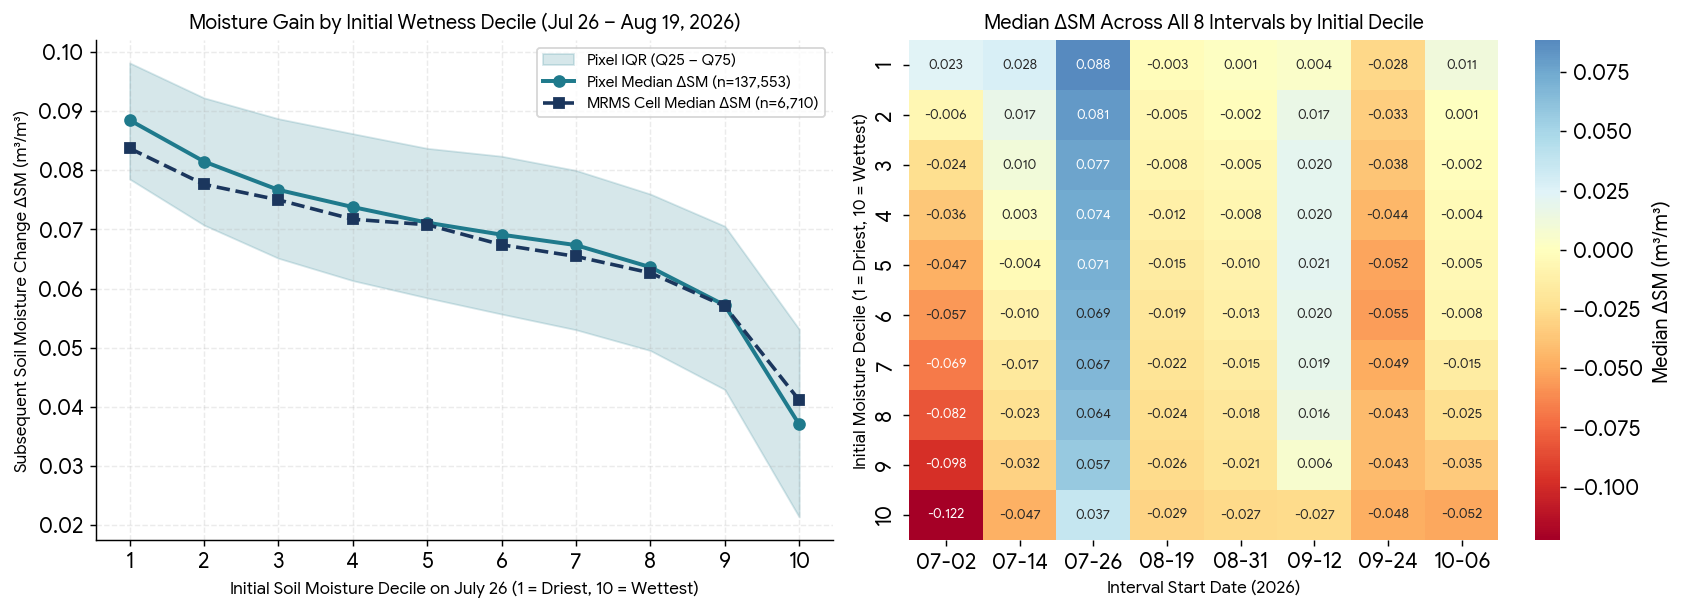

In [12]:
dec_pix = load_csv("summaries/initial_moisture_deciles_pixels.csv")
dec_cell = load_csv("summaries/initial_moisture_deciles_mrms_cells.csv")
init_sum = load_json("summaries/initial_moisture_summary.json")
int_dec = load_csv("summaries/interval_deciles.csv")

print("=== July 26 – August 19 Initial Moisture Deciles (Pixel Level, n = 13,755–13,756/decile) ===")
print(dec_pix[['decile', 'initial_median', 'final_median', 'change_median', 'change_mean', 'fraction_wetter']].to_string(index=False, float_format=lambda x: f"{x:.4f}"))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.2, 4.8))

# Panel 1: Jul 26 - Aug 19 Change across Initial Moisture Deciles (Pixels vs MRMS cells)
ax1.fill_between(
    dec_pix['decile'], dec_pix['change_q25'], dec_pix['change_q75'],
    color=PALETTE['teal'], alpha=0.18, label='Pixel IQR (Q25 – Q75)'
)
ax1.plot(
    dec_pix['decile'], dec_pix['change_median'],
    color=PALETTE['teal'], marker='o', linewidth=2.2, label='Pixel Median ΔSM (n=137,553)'
)
ax1.plot(
    dec_cell['decile'], dec_cell['change_median'],
    color=PALETTE['navy'], marker='s', linestyle='--', linewidth=2.0, label='MRMS Cell Median ΔSM (n=6,710)'
)
ax1.set_xticks(range(1, 11))
ax1.set_xlabel('Initial Soil Moisture Decile on July 26 (1 = Driest, 10 = Wettest)', fontsize=9.5)
ax1.set_ylabel('Subsequent Soil Moisture Change ΔSM (m³/m³)', fontsize=9.5)
ax1.set_title('Moisture Gain by Initial Wetness Decile (Jul 26 – Aug 19, 2026)', fontsize=11, fontweight='bold')
ax1.legend(loc='upper right', frameon=True, facecolor='white', fontsize=8.5)

# Panel 2: Heatmap of Median ΔSM across all 8 intervals and all 10 initial deciles
piv_dec = int_dec.pivot(index='decile', columns='start_date', values='change_median')
piv_dec.columns = [f"{c[5:]}" for c in piv_dec.columns]
sns.heatmap(
    piv_dec, cmap='RdYlBu', center=0.0, annot=True, fmt='.3f',
    annot_kws={'size': 7.5}, cbar_kws={'label': 'Median ΔSM (m³/m³)'}, ax=ax2
)
ax2.set_title('Median ΔSM Across All 8 Intervals by Initial Decile', fontsize=11, fontweight='bold')
ax2.set_xlabel('Interval Start Date (2026)', fontsize=9.5)
ax2.set_ylabel('Initial Moisture Decile (1 = Driest, 10 = Wettest)', fontsize=9.5)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig4_initial_moisture_deciles.png")
plt.show()

## 6. Scientific Interpretation & Key Limitations
To ensure rigorous communication in both our web observatory and hackathon presentation, we distinguish verified empirical findings from methodological boundaries:

| Domain | Verified Observation | Critical Scientific Caveat |
| :--- | :--- | :--- |
| **NISAR L3 SME2** | Captures basin-wide surface wetting (`+0.0682 m³/m³` in Aug) and autumn drying (`-0.0440 m³/m³` in late Sep) across `137,553` common pixels. | Measures **top ~0–5 cm soil moisture** at discrete 12–24 day snapshots—**not** deep aquifer water levels or continuous daily moisture. |
| **NOAA MRMS Rainfall** | Strong temporal coupling with $\Delta\text{SM}$ ($r = 0.8167$ for prior 7-day rainfall, $-0.54$ without the storm interval) and clear west-to-east gradient in mid-September. | Parquet values are empirically interpreted in **inches** (cross-checked vs. Champaign ICN gauge on Aug 15: `1.477 in` vs. `1.380 in`); missing files indicate sparse dry-hour omission. |
| **Antecedent Wetness** | Driest Decile 1 gained `+0.0880 m³/m³` vs. `+0.0373 m³/m³` in wettest Decile 10 during Jul 26 – Aug 19. | Direct correlation between $\text{SM}_{\text{initial}}$ and $\Delta\text{SM}$ (`r = -0.592`) includes structural mathematical coupling; initial and final moisture remain positively correlated (`r = +0.598`). |
| **USDA Crop Context** | Provides regional agricultural context (corn/soybean row-crop dominance across central Illinois). | Reference CDL layer is from **2025**, whereas NISAR observations are from **2026**; annual crop rotation prevents field-level 2026 crop verification without 2026 ground truth. |
| **ISWS Groundwater** | Shows pronounced summer pumping/drawdown seasonality (`62.2%` of rapid events in Jun–Sep) and depth-dependent head responses. | Drawdown/recovery signatures are observational; telemetry alone does not attribute pumping to specific municipal vs. irrigation wells. |

## 7. Supporting Extension: ISWS Groundwater Dynamics & Historical Seasonality
While NISAR monitors near-surface soil moisture, the **Illinois State Water Survey (ISWS)** observation network tracks hydraulic head inside the underlying **Mahomet** (`150–350 ft` deep, predominantly confined) and overlying **Glasford / Henry** (`60–175 ft`) aquifers:
- **Co-Located Paired Wells (`7` pairs, `14` wells in `pair_metadata.csv`):** Comparing deep Mahomet wells against adjacent shallower Glasford/Henry wells over the `109-day` study window (`2026-07-02` to `2026-10-18`) demonstrates distinct hydraulic responses—for example, at `CHAM-08-02`, the shallow Glasford well (`75 ft`) dropped **-2.02 ft** (`amplitude 5.86 ft`) over summer, whereas the co-located deep Mahomet well (`315 ft`) remained nearly flat (**-0.03 ft** net change).
- **12-Year Historical Seasonality (`2015–2026`, `1,424` candidate drawdown/recovery events across `31` wells):** Rapid drawdown events ($\ge 0.50\text{ ft}$ drop followed by recovery within $\le 48\text{ hours}$) peak sharply in **July** (**309 events**, mean rate **0.73 events per 30 valid days**) and **June–August** (**759 events**, mean drop **1.32–1.34 ft**), compared to winter/spring lows (`0.08–0.17` events/30 days).

=== 2026 Paired Well Comparison (Mahomet vs. Glasford / Henry, Jul 2 – Oct 18) ===
       well  aquifer  depth  net_change_ft  amplitude_ft
CHAM-08-02A  MAHOMET 315.00          -0.03          2.60
CHAM-08-02B GLASFORD  75.00          -2.02          5.86
 CHAM-08-06 GLASFORD 172.50          -0.23          0.79
CHAM-08-08A GLASFORD 350.00           0.09          2.00
CHAM-08-08B GLASFORD 100.50          -2.08          5.07
CHAM-09-03A  MAHOMET 308.00          -0.24          5.31
CHAM-09-03C    HENRY  61.00          -1.36          1.68
    CHM-95B GLASFORD 304.00          -0.16          3.70
    MTH-22A  MAHOMET 237.00          -0.41          1.43
    MTH-22B  MAHOMET 157.00          -6.18          7.64
    MTOW-11 GLASFORD  63.00           0.46          0.99
    MTOW-14  MAHOMET 215.00          -0.54          3.09
PIAT-09-01A  MAHOMET 321.00          -2.88          6.37
PIAT-09-01B GLASFORD 136.00          -1.75          4.73


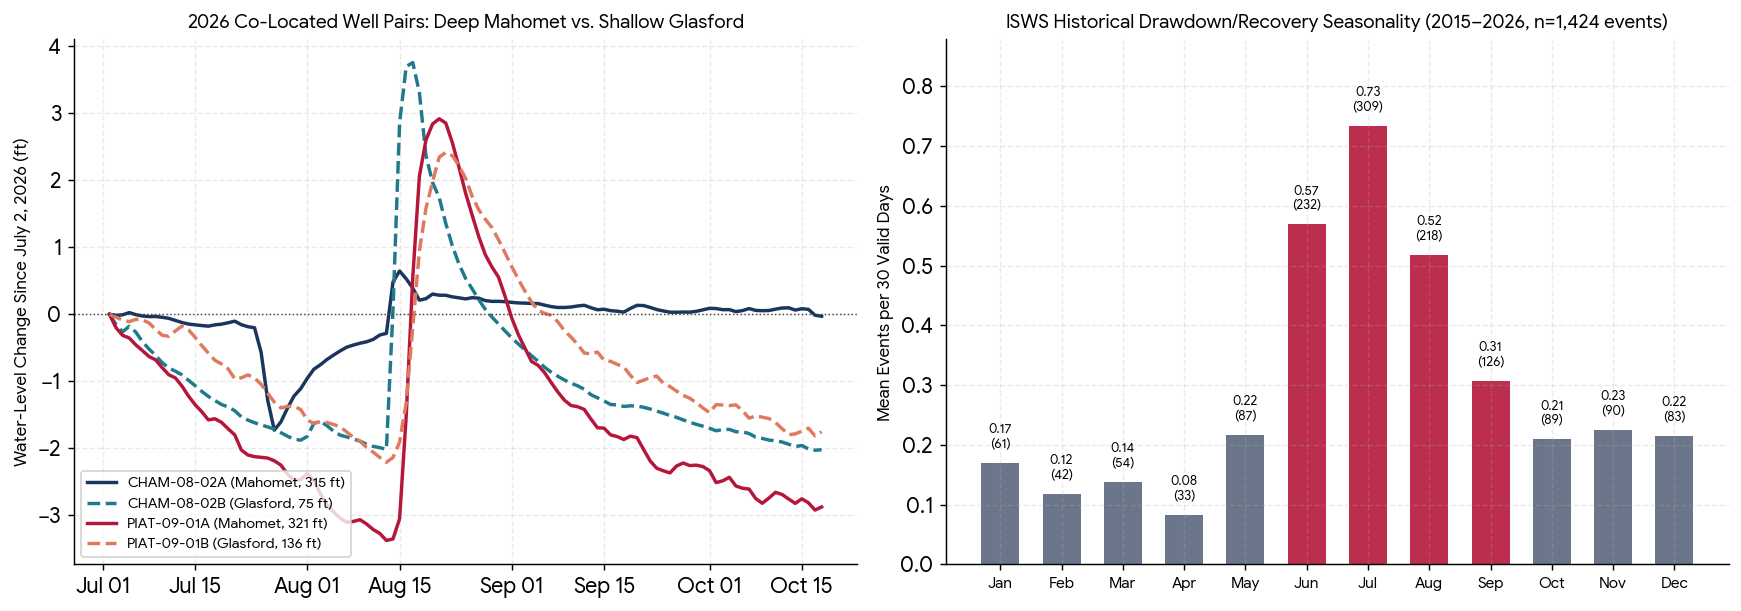

In [15]:
# Load ISWS 2026 daily groundwater series, paired wells, and 2015-2026 historical event rates
gw_daily = load_csv("wells/daily_groundwater_2026.csv")
pairs_df = load_csv("wells/pair_metadata.csv")
hist_rates = load_csv("wells/monthly_event_rates.csv")
cand_events = load_csv("wells/candidate_events.csv")

# Summarize 2026 seasonal amplitude across the 47 active telemetry wells
gw_sorted = gw_daily.sort_values(['well', 'date_utc'])
well_2026_summary = gw_sorted.groupby('well').agg(
    days=('date_utc', 'count'),
    first_elev=('mean_elevation', 'first'),
    last_elev=('mean_elevation', 'last'),
    min_elev=('min_elevation', 'min'),
    max_elev=('max_elevation', 'max')
).reset_index()
well_2026_summary['net_change_ft'] = well_2026_summary['last_elev'] - well_2026_summary['first_elev']
well_2026_summary['amplitude_ft'] = well_2026_summary['max_elev'] - well_2026_summary['min_elev']
well_2026_summary = well_2026_summary.merge(wells_df[['well', 'aquifer', 'depth', 'network']], on='well', how='left')

print("=== 2026 Paired Well Comparison (Mahomet vs. Glasford / Henry, Jul 2 – Oct 18) ===")
pair_wells = list(pairs_df['well_a']) + list(pairs_df['well_b'])
print(well_2026_summary[well_2026_summary['well'].isin(pair_wells)][
    ['well', 'aquifer', 'depth', 'net_change_ft', 'amplitude_ft']
].sort_values(['well']).to_string(index=False, float_format=lambda x: f"{x:.2f}"))

# Figure 5: Paired well anomaly time series + 12-year monthly event seasonality
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.5, 4.8))

# Panel 1: Normalized water-level anomaly (relative to July 2, 2026) for two contrasting pairs
example_wells = [
    ('CHAM-08-02A', 'CHAM-08-02A (Mahomet, 315 ft)', PALETTE['navy'], '-'),
    ('CHAM-08-02B', 'CHAM-08-02B (Glasford, 75 ft)', PALETTE['teal'], '--'),
    ('PIAT-09-01A', 'PIAT-09-01A (Mahomet, 321 ft)', PALETTE['crimson'], '-'),
    ('PIAT-09-01B', 'PIAT-09-01B (Glasford, 136 ft)', PALETTE['amber'], '--'),
]
for w_id, w_label, col, ls in example_wells:
    sub = gw_sorted[gw_sorted['well'] == w_id].copy()
    sub['dt'] = pd.to_datetime(sub['date_utc'])
    sub['anom_ft'] = sub['mean_elevation'] - sub['mean_elevation'].iloc[0]
    ax1.plot(sub['dt'], sub['anom_ft'], label=w_label, color=col, linestyle=ls, linewidth=1.9)

ax1.axhline(0, color='#444444', linewidth=0.8, linestyle=':')
ax1.xaxis.set_major_formatter(mdates.DateFormatter('%b %d'))
ax1.set_title('2026 Co-Located Well Pairs: Deep Mahomet vs. Shallow Glasford', fontsize=10.5, fontweight='bold')
ax1.set_ylabel('Water-Level Change Since July 2, 2026 (ft)', fontsize=9.5)
ax1.legend(loc='lower left', frameon=True, facecolor='white', fontsize=8)

# Panel 2: Historical monthly drawdown/recovery event rate (2015 - 2026)
m_stats = hist_rates.groupby('month').agg(
    mean_rate=('events_per_30_valid_days', 'mean'),
    total_events=('candidate_events', 'sum')
).reset_index()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun', 'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
m_colors = [PALETTE['crimson'] if m in [6, 7, 8, 9] else PALETTE['slate'] for m in m_stats['month']]

mbars = ax2.bar(m_stats['month'], m_stats['mean_rate'], color=m_colors, width=0.62, alpha=0.9)
ax2.set_xticks(range(1, 13))
ax2.set_xticklabels(month_names, fontsize=8.5)
ax2.set_ylabel('Mean Events per 30 Valid Days', fontsize=9.5)
ax2.set_ylim(0, 0.88)
ax2.set_title('ISWS Historical Drawdown/Recovery Seasonality (2015–2026, n=1,424 events)', fontsize=10.5, fontweight='bold')

for b, rate, cnt in zip(mbars, m_stats['mean_rate'], m_stats['total_events']):
    ax2.text(b.get_x() + b.get_width()/2, rate + 0.02, f"{rate:.2f}\n({int(cnt)})", ha='center', va='bottom', fontsize=7.2)

plt.tight_layout()
plt.savefig(f"{FIG_DIR}/fig5_isws_groundwater_seasonality.png")
plt.show()